# Jupyter Notebook demonstrating how mpsim can be called from within Python
Roelof Rietbroek, June 2025, r.rietbroek@utwente.nl

This notebook reproduces and example from the [snr_demo.html](snr_demo.html) supplied in the mpsim repository

In [1]:
%load_ext autoreload
%autoreload 2

## Loading mpsim Octave/Matlab functions
Octave matlab functions can be loaded for use in Python through the `pympsim.oct` submodule


In [1]:
#note:loading the module can take a moment because an Octave session will be started to communicate with
from pympsim.oct import snr_settings,snr_setup,snr_fwd
from pympsim.plot import snr_plot

## Capturing additional Octave output
If the output from the Octave console and that from the pympsim wrapper functions is to be called you can execute the cell below

In [19]:
from pympsim.logging import setInfoLevel
# Setinflovel to capture more output from the octave console
setInfoLevel()

## Configure and compute Scenario 1 (L2 frequency)

In [2]:
sett_a=snr_settings()
sett_a['opt']['freq_name'] = 'L2'
sett_a['opt']['code_name'] = 'L2C'

setup_a=snr_setup(sett_a)

res_a=snr_fwd(setup_a)


## Configure and compute Scenario 2 (L1 frequency)

In [3]:
# change some of the settings
sett_b=sett_a
#note: sett_b acts like an dictionary but attributes can also be referred to like below
sett_b.opt.freq_name = 'L1';
sett_b.opt.code_name = 'C/A';


setup_b = snr_setup (sett_b);
res_b = snr_fwd (setup_b);


## Use Python plotting facilities to visualize the result

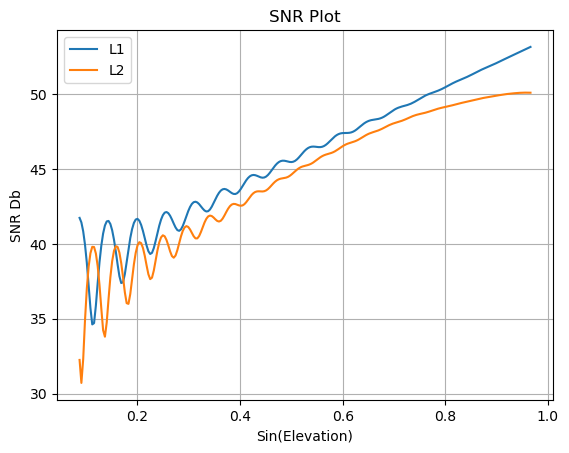

In [4]:
 
ax=snr_plot(res_a,label='L1',xscale='sine')
#add the second simulation to the plot
snr_plot(res_b,ax=ax,label='L2',xscale='sine')

#The snr_plot a Matplotlib axis, on which additional operations can be applied e.g.: 
ax.grid()

## Calling mpsim's plotting functions
Calling functions which generate plots also works, but a new figure window will be opened using the active octave's graphic toolkit

In [5]:
from pympsim.oct import snr_demo_plot2

In [6]:
snr_demo_plot2(res_b,res_a)